In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

In [ ]:
from keras.datasets import cifar10
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [ ]:
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (50000, 32, 32, 3)
Testing data shape: (10000, 32, 32, 3)


In [ ]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

In [ ]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(10, activation="softmax")
])

In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
model.summary()

history = model.fit(
    x_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,608 (1.83 MB)

 Trainable params: 160,202 (625.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 320,406 (1.22 MB)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.7531 - loss: 0.7096 - val_accuracy: 0.7380 - val_loss: 0.7724
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.7607 - loss: 0.6826 - val_accuracy: 0.7356 - val_loss: 0.7815
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 48ms/step - accuracy: 0.7735 - loss: 0.6472 - val_accuracy: 0.7304 - val_loss: 0.7932
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.7818 - loss: 0.6204 - val_accuracy: 0.7208 - val_loss: 0.8292
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.7927 - loss: 0.5936 - val_accuracy: 0.7388 - val_loss: 0.7953
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 34s 48ms/step - accuracy: 0.7959 - loss: 0.5756 - val_accuracy: 0.7454 - val_loss: 0.7768
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - accuracy: 0.8044 - loss: 0.5498 - val_accuracy: 0.7470 - val_loss: 0.8103
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.8095 - loss: 0.5330 - 

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test_cat)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7101 - loss: 0.8455
Test Loss: 0.8455408215522766
Test Accuracy: 0.710099995136261


In [ ]:
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = y_test.flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


In [ ]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

In [ ]:
confusion_matrix = tf.math.confusion_matrix(labels=y_true, predictions=y_pred_classes)
confusion_matrix

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[843,  11,  18,   8,  18,   2,   8,  16,  43,  33],
       [ 23, 803,   3,   8,   5,   1,  14,   7,  36, 100],
       [115,   3, 516,  62,  96,  54,  75,  55,  11,  13],
       [ 35,   8,  72, 489,  85, 136,  65,  72,   8,  30],
       [ 44,   1,  61,  40, 647,  14,  45, 137,   8,   3],
       [ 18,   4,  67, 144,  49, 550,  29, 124,   3,  12],
       [  7,   5,  45,  52,  49,   7, 799,  14,   8,  14],
       [ 17,   3,  25,  22,  33,  29,   9, 845,   2,  15],
       [114,  27,   5,  14,   8,   2,   6,   5, 772,  47],
       [ 35,  48,   7,   6,   8,   3,   9,  30,  17, 837]], dtype=int32)>

Text(95.72222222222221, 0.5, 'Actual')

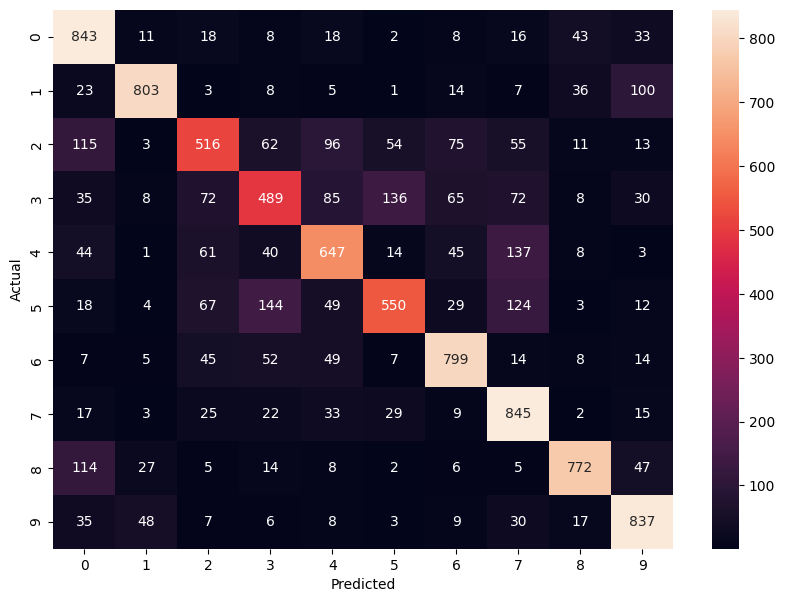

In [ ]:
cm=tf.math.confusion_matrix(labels=y_true,predictions=y_pred_classes)
plt.figure(figsize=(10,7))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')

In [ ]:
print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred_classes,
        target_names=class_names
    )
)


Classification Report:
              precision    recall  f1-score   support

    airplane       0.67      0.84      0.75      1000
  automobile       0.88      0.80      0.84      1000
        bird       0.63      0.52      0.57      1000
         cat       0.58      0.49      0.53      1000
        deer       0.65      0.65      0.65      1000
         dog       0.69      0.55      0.61      1000
        frog       0.75      0.80      0.78      1000
       horse       0.65      0.84      0.73      1000
        ship       0.85      0.77      0.81      1000
       truck       0.76      0.84      0.80      1000

    accuracy                           0.71     10000
   macro avg       0.71      0.71      0.71     10000
weighted avg       0.71      0.71      0.71     10000

